In [1]:
# ======================================================
# Import Libraries
# ======================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="darkgrid")

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ======================================================
# Load Processed Data
# ======================================================

prices = pd.read_csv(
    "data/processed/clean_prices.csv",
    index_col=0,
    parse_dates=True
)

daily_returns = pd.read_csv(
    "data/processed/daily_returns.csv",
    index_col=0,
    parse_dates=True
)

log_returns = pd.read_csv(
    "data/processed/log_returns.csv",
    index_col=0,
    parse_dates=True
)

print(prices.shape)
print(daily_returns.shape)

(4170, 50)
(4170, 50)


In [3]:
display(prices.head())
display(daily_returns.head())

,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,...,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,6.406480,NaN,18.078800,30.856331,37.090000,9.70,38.748535,6.6950,12.038228,156.575027,...,31.051466,30.674999,6.585601,NaN,16.852434,24.269079,32.952579,19.564676,12.909191,37.377274
2010-01-05,6.417557,NaN,17.932741,31.047039,37.700001,9.71,38.412888,6.7345,12.429532,157.250992,...,31.798971,30.216772,6.553343,NaN,16.755251,24.230591,33.009216,19.340479,12.780644,37.523228
2010-01-06,6.315476,NaN,18.032322,31.377081,37.619999,9.57,38.124214,6.6125,12.575309,154.008942,...,31.488070,30.058334,6.488967,NaN,16.632149,24.469208,32.765671,19.080770,12.752076,37.847534
2010-01-07,6.303801,NaN,18.181707,31.347752,36.889999,9.47,37.775131,6.5000,12.989630,155.702164,...,32.400963,30.186798,6.416109,NaN,16.683985,25.408251,32.516449,19.258343,12.759222,37.728611
2010-01-08,6.345710,NaN,18.274662,31.223068,36.689999,9.43,38.110790,6.6760,12.874540,156.798187,...,32.725090,30.246746,6.369104,NaN,17.066256,25.169643,34.079678,19.311613,12.694949,37.577274


,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,...,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.001729,NaN,-0.008079,0.006181,0.016446,0.001031,-0.008662,0.005900,0.032505,0.004317,...,0.024073,-0.014938,-0.004898,NaN,-0.005767,-0.001586,0.001719,-0.011459,-0.009958,0.003905
2010-01-06,-0.015906,NaN,0.005553,0.010630,-0.002122,-0.014418,-0.007515,-0.018116,0.011728,-0.020617,...,-0.009777,-0.005243,-0.009823,NaN,-0.007347,0.009848,-0.007378,-0.013428,-0.002235,0.008643
2010-01-07,-0.001849,NaN,0.008284,-0.000935,-0.019405,-0.010449,-0.009156,-0.017013,0.032947,0.010994,...,0.028992,0.004274,-0.011228,NaN,0.003117,0.038377,-0.007606,0.009306,0.000560,-0.003142
2010-01-08,0.006648,NaN,0.005113,-0.003977,-0.005422,-0.004224,0.008886,0.027077,-0.008860,0.007039,...,0.010004,0.001986,-0.007326,NaN,0.022912,-0.009391,0.048075,0.002766,-0.005037,-0.004011


In [4]:
# ======================================================
# Portfolio Configuration
# ======================================================

stocks = daily_returns.columns.tolist()

num_stocks = len(stocks)

print("Number of Stocks :", num_stocks)

Number of Stocks : 50


In [5]:
# ======================================================
# Equal Weight Portfolio
# ======================================================

weights = np.repeat(
    1/num_stocks,
    num_stocks
)

portfolio_weights = pd.DataFrame({

    "Stock":stocks,

    "Weight":weights

})

portfolio_weights.head()

,Stock,Weight
0,AAPL,0.02
1,ABBV,0.02
2,ABT,0.02
3,ACN,0.02
4,ADBE,0.02


In [6]:
portfolio_weights

,Stock,Weight
0,AAPL,0.02
1,ABBV,0.02
2,ABT,0.02
3,ACN,0.02
4,ADBE,0.02
5,AMD,0.02
6,AMGN,0.02
7,AMZN,0.02
8,BAC,0.02
9,BLK,0.02


In [7]:
print("Total Weight :", portfolio_weights["Weight"].sum())

Total Weight : 1.0


In [8]:
# ======================================================
# Portfolio Returns
# ======================================================

portfolio_returns = daily_returns.dot(weights)

portfolio_returns.head()

Date
2010-01-04   NaN
2010-01-05   NaN
2010-01-06   NaN
2010-01-07   NaN
2010-01-08   NaN
dtype: float64

In [9]:
portfolio_returns.describe()

count    3415.000000
mean        0.000797
std         0.010801
min        -0.122276
25%        -0.003712
50%         0.001065
75%         0.006145
max         0.101052
dtype: float64

In [10]:
# ======================================================
# Portfolio Value
# ======================================================

initial_investment = 100000

portfolio_value = (

    1 + portfolio_returns

).cumprod() * initial_investment

portfolio_value.head()

Date
2010-01-04   NaN
2010-01-05   NaN
2010-01-06   NaN
2010-01-07   NaN
2010-01-08   NaN
dtype: float64

In [11]:
# ======================================================
# Daily Profit & Loss
# ======================================================

portfolio_pnl = portfolio_value.diff()

portfolio_pnl.head()

Date
2010-01-04   NaN
2010-01-05   NaN
2010-01-06   NaN
2010-01-07   NaN
2010-01-08   NaN
dtype: float64

In [12]:
# ======================================================
# Rolling Volatility
# ======================================================

rolling_volatility = (

    portfolio_returns

    .rolling(30)

    .std()

)

rolling_volatility.head()

Date
2010-01-04   NaN
2010-01-05   NaN
2010-01-06   NaN
2010-01-07   NaN
2010-01-08   NaN
dtype: float64

In [13]:
# ======================================================
# Drawdown
# ======================================================

running_max = portfolio_value.cummax()

drawdown = (

    portfolio_value

    - running_max

)/running_max

drawdown.head()

Date
2010-01-04   NaN
2010-01-05   NaN
2010-01-06   NaN
2010-01-07   NaN
2010-01-08   NaN
dtype: float64

In [14]:
# ======================================================
# Annualized Return
# ======================================================

annual_return = (

    portfolio_returns.mean()

)*252

annual_volatility = (

    portfolio_returns.std()

)*np.sqrt(252)

print("Annual Return :",annual_return)

print("Annual Volatility :",annual_volatility)

Annual Return : 0.20090740057111744
Annual Volatility : 0.17146611203846737


In [15]:
# ======================================================
# Sharpe Ratio
# ======================================================

risk_free_rate = 0.04

sharpe = (

annual_return-risk_free_rate

)/annual_volatility

print("Sharpe Ratio :",sharpe)

Sharpe Ratio : 0.9384210014339093


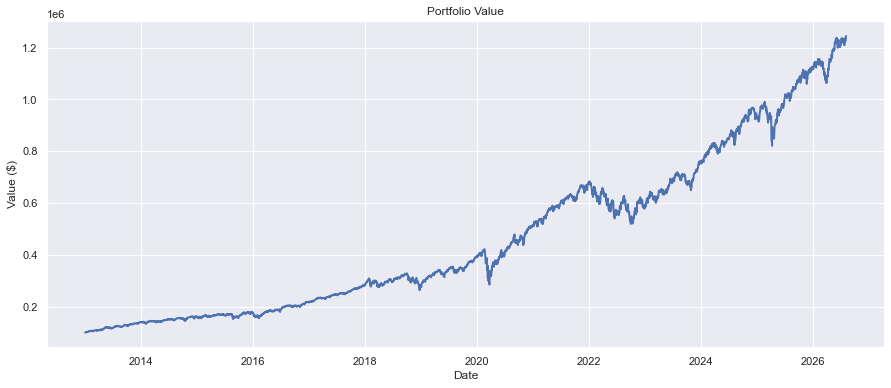

In [16]:
plt.figure(figsize=(15,6))

plt.plot(

portfolio_value,

linewidth=2

)

plt.title(

"Portfolio Value"

)

plt.xlabel("Date")

plt.ylabel("Value ($)")

plt.show()

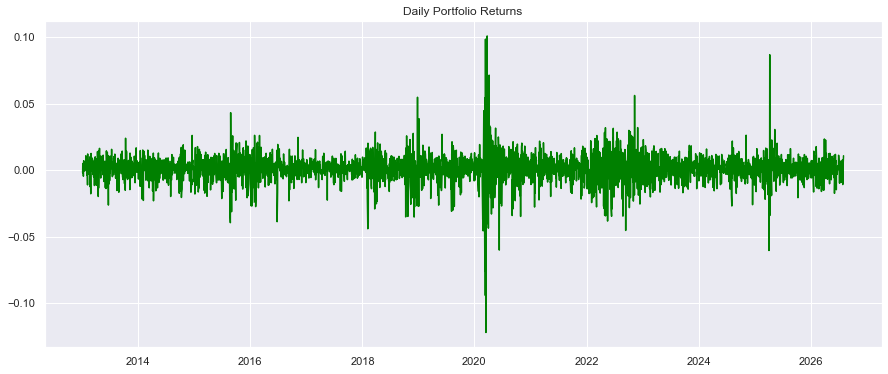

In [17]:
plt.figure(figsize=(15,6))

plt.plot(

portfolio_returns,

color="green"

)

plt.title(

"Daily Portfolio Returns"

)

plt.show()

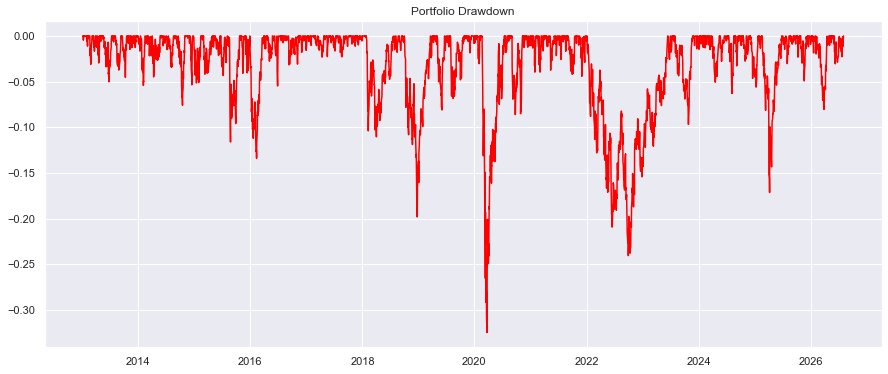

In [18]:
plt.figure(figsize=(15,6))

plt.plot(

drawdown,

color="red"

)

plt.title(

"Portfolio Drawdown"

)

plt.show()

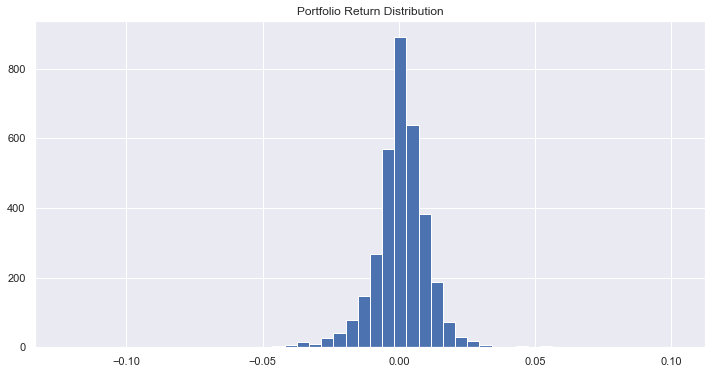

In [19]:
plt.figure(figsize=(12,6))

plt.hist(

portfolio_returns,

bins=50

)

plt.title(

"Portfolio Return Distribution"

)

plt.show()

In [20]:
portfolio_returns.to_csv(

"data/processed/portfolio_returns.csv"

)

portfolio_value.to_csv(

"data/processed/portfolio_value.csv"

)

portfolio_pnl.to_csv(

"data/processed/portfolio_pnl.csv"

)

portfolio_weights.to_csv(

"data/processed/portfolio_weights.csv",

index=False

)

print("Portfolio Outputs Saved")

Portfolio Outputs Saved


In [21]:
print("="*50)

print("PHASE 3 COMPLETED")

print("="*50)

print()

print("Generated Files")

print("✔ portfolio_returns.csv")

print("✔ portfolio_value.csv")

print("✔ portfolio_pnl.csv")

print("✔ portfolio_weights.csv")

print()

print("Ready for Phase 4 : Historical VaR")

PHASE 3 COMPLETED

Generated Files
✔ portfolio_returns.csv
✔ portfolio_value.csv
✔ portfolio_pnl.csv
✔ portfolio_weights.csv

Ready for Phase 4 : Historical VaR
